# Thực hành: phân loại dữ liệu Balance Scale bằng cây quyết định

*Bài 6, mục 6.2.* Bộ dữ liệu **Balance Scale** (UCI Machine Learning Repository) mô tả 625 trạng thái của một chiếc cân đĩa. Mỗi mẫu có 4 thuộc tính, mỗi thuộc tính nhận giá trị nguyên từ 1 đến 5:
- `left-weight`, `left-distance`: khối lượng và khoảng cách từ vật tới trục ở đĩa trái;
- `right-weight`, `right-distance`: tương tự ở đĩa phải.

Nhãn `class`: `L` (cân lệch trái), `B` (cân bằng), `R` (cân lệch phải).

File `../data/balance_scale.csv` tải từ https://archive.ics.uci.edu/static/public/12/data.csv, giữ nguyên tên cột gốc.

## 1. Đọc và khám phá dữ liệu

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('..') / 'data'   # notebook chạy trong codes/
data = pd.read_csv(DATA / 'balance_scale.csv')
print('Kích thước:', data.shape)
data.head()

Kích thước: (625, 5)


,class,left-weight,left-distance,right-weight,right-distance
0,B,1,1,1,1
1,R,1,1,1,2
2,R,1,1,1,3
3,R,1,1,1,4
4,R,1,1,1,5


In [2]:
print(data.isnull().sum().sum(), 'giá trị thiếu')
print(data['class'].value_counts())

0 giá trị thiếu
class
R    288
L    288
B     49
Name: count, dtype: int64


Lớp `B` chỉ chiếm khoảng 8% dữ liệu: dữ liệu **mất cân bằng**, cần chú ý Recall của lớp này.

## 2. Tách thuộc tính và nhãn, chia tập huấn luyện/kiểm tra

Như giáo trình: 70% huấn luyện, 30% kiểm tra, `random_state=100`. Thêm `stratify=y` để tỉ lệ các lớp ở hai tập giống nhau.

In [3]:
from sklearn.model_selection import train_test_split

feature_names = ['left-weight', 'left-distance', 'right-weight', 'right-distance']
X = data[feature_names].to_numpy()
y = data['class'].to_numpy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=100, stratify=y)
print('Huấn luyện:', X_train.shape, ' kiểm tra:', X_test.shape)

Huấn luyện: (437, 4)  kiểm tra: (188, 4)


## 3. Huấn luyện cây với tiêu chí Gini và Entropy

Tham số theo giáo trình: `max_depth=3`, `min_samples_leaf=5` (cắt tỉa trước).

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

models = {}
for criterion in ['gini', 'entropy']:
    model = DecisionTreeClassifier(criterion=criterion, max_depth=3, min_samples_leaf=5, random_state=100)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    models[criterion] = model
    print('===== criterion = %s =====' % criterion)
    print('Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán; thứ tự %s):' % list(model.classes_))
    print(confusion_matrix(y_test, y_pred, labels=model.classes_))
    print('Accuracy: %.4f' % accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred, zero_division=0))

===== criterion = gini =====
Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán; thứ tự ['B', 'L', 'R']):
[[ 0  8  7]
 [ 0 67 20]
 [ 0 17 69]]
Accuracy: 0.7234
              precision    recall  f1-score   support

           B       0.00      0.00      0.00        15
           L       0.73      0.77      0.75        87
           R       0.72      0.80      0.76        86

    accuracy                           0.72       188
   macro avg       0.48      0.52      0.50       188
weighted avg       0.67      0.72      0.69       188

===== criterion = entropy =====
Ma trận nhầm lẫn (hàng: thực tế, cột: dự đoán; thứ tự ['B', 'L', 'R']):
[[ 0  8  7]
 [ 0 67 20]
 [ 0 17 69]]
Accuracy: 0.7234
              precision    recall  f1-score   support

           B       0.00      0.00      0.00        15
           L       0.73      0.77      0.75        87
           R       0.72      0.80      0.76        86

    accuracy                           0.72       188
   macro avg       0.48      0.52 

Cả hai cây đều **không dự đoán được lớp `B`** (Recall = 0): với độ sâu 3, cây chỉ đủ để phân biệt L và R.

## 4. Trực quan hóa cây

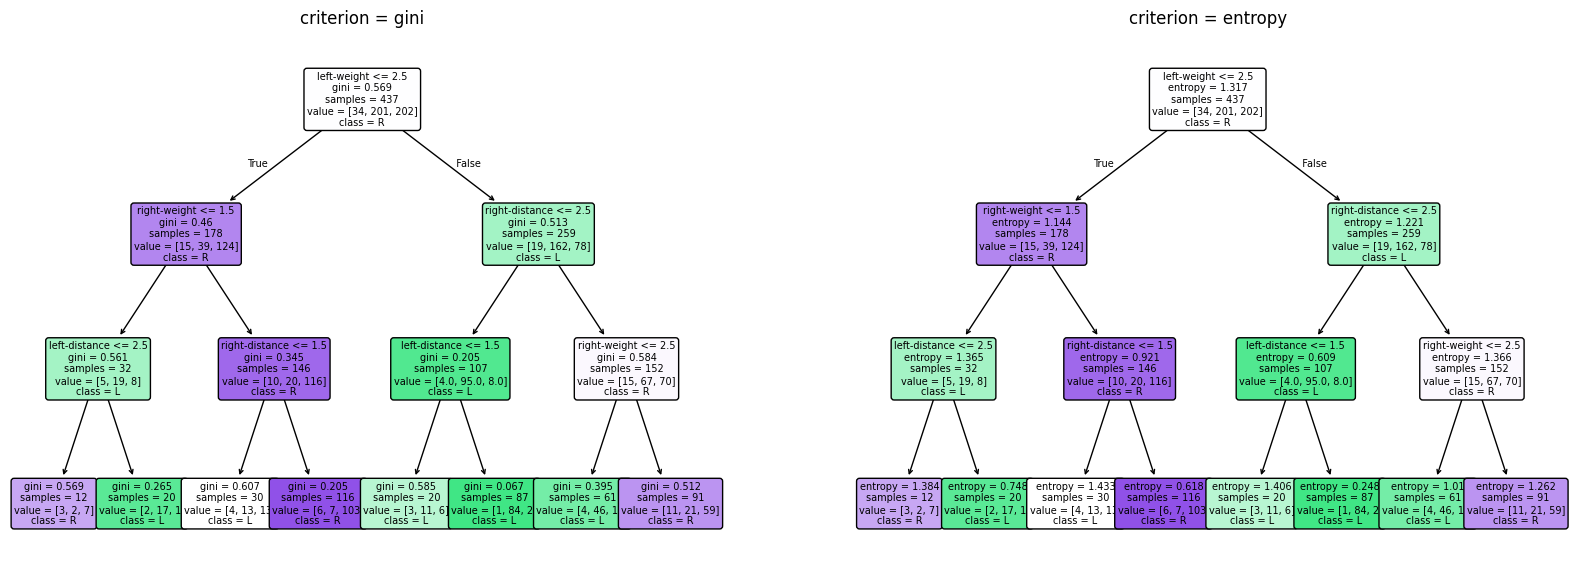

In [5]:
from sklearn.tree import plot_tree

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
for ax, criterion in zip(axes, ['gini', 'entropy']):
    plot_tree(models[criterion], feature_names=feature_names, class_names=list(models[criterion].classes_),
              filled=True, rounded=True, fontsize=7, ax=ax)
    ax.set_title('criterion = %s' % criterion)
plt.show()

## 5. Chọn siêu tham số bằng kiểm định chéo

In [6]:
from sklearn.model_selection import GridSearchCV

param_grid = {'criterion': ['gini', 'entropy'],
              'max_depth': [3, 4, 5, 6, 8, 10, None],
              'min_samples_leaf': [1, 2, 5, 10]}
search = GridSearchCV(DecisionTreeClassifier(random_state=100), param_grid, cv=5)
search.fit(X_train, y_train)
print('Siêu tham số tốt nhất:', search.best_params_)
print('Độ chính xác kiểm định chéo: %.4f' % search.best_score_)
best = search.best_estimator_
y_pred = best.predict(X_test)
print('Độ sâu %d, %d nút lá' % (best.get_depth(), best.get_n_leaves()))
print('Accuracy kiểm tra: %.4f' % accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Siêu tham số tốt nhất: {'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 5}
Độ chính xác kiểm định chéo: 0.8010
Độ sâu 8, 41 nút lá
Accuracy kiểm tra: 0.7819
              precision    recall  f1-score   support

           B       0.15      0.13      0.14        15
           L       0.82      0.86      0.84        87
           R       0.83      0.81      0.82        86

    accuracy                           0.78       188
   macro avg       0.60      0.60      0.60       188
weighted avg       0.77      0.78      0.78       188



Độ quan trọng của đặc trưng (`feature_importances_`): tổng mức giảm độ vẩn đục do mỗi đặc trưng đóng góp, chuẩn hóa để tổng bằng 1.

In [7]:
for name, importance in zip(feature_names, best.feature_importances_):
    print('%-15s %.3f' % (name, importance))

left-weight     0.224
left-distance   0.288
right-weight    0.247
right-distance  0.240


## 6. Thiết kế đặc trưng: mô-men lực

Theo vật lý, cân lệch về phía có mô-men lực (khối lượng × khoảng cách) lớn hơn. Cây quyết định chỉ chia theo từng đặc trưng với ngưỡng song song trục nên phải dùng rất nhiều nút để xấp xỉ quan hệ nhân này. Thêm đặc trưng `moment_difference` = mô-men trái − mô-men phải (Bài 2: thiết kế đặc trưng):

In [8]:
def add_moment(X):
    left_moment = X[:, 0] * X[:, 1]      # mô-men lực đĩa trái
    right_moment = X[:, 2] * X[:, 3]     # mô-men lực đĩa phải
    return np.column_stack([X, left_moment - right_moment])


tree = DecisionTreeClassifier(random_state=100).fit(add_moment(X_train), y_train)
y_pred = tree.predict(add_moment(X_test))
print('Độ sâu %d, %d nút lá' % (tree.get_depth(), tree.get_n_leaves()))
print('Accuracy kiểm tra: %.4f' % accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred, labels=tree.classes_))

Độ sâu 2, 3 nút lá
Accuracy kiểm tra: 1.0000
[[15  0  0]
 [ 0 87  0]
 [ 0  0 86]]


In [9]:
from sklearn.tree import export_text

print(export_text(tree, feature_names=feature_names + ['moment_difference']))

|--- moment_difference <= -0.50
|   |--- class: R
|--- moment_difference >  -0.50
|   |--- moment_difference <= 0.50
|   |   |--- class: B
|   |--- moment_difference >  0.50
|   |   |--- class: L

